# Intervals

Many analyses look at stretches of data rather than single time points:
the second after a stimulus, the time between trial start and response,
blinks, or periods with bad data. In `pypillometry`, such stretches are
stored as `Intervals`, a list of (start, end) pairs with their units and,
if they belong to events, the event labels.

This tutorial shows where intervals come from, how to change and combine
them, and how to use them in an analysis.

In [1]:
import pypillometry as pp
from pypillometry import u
import numpy as np
import matplotlib.pyplot as plt

pp.logging_set_level("WARNING")

d = pp.get_example_data("rlmw_002_short")

## Intervals around events

`get_intervals()` creates one interval for each selected event. The first
argument selects the events (a string contained in the label, a function,
or an `Events` object; see the [Events tutorial](events.ipynb)). The
second gives the window relative to the event onset, here from 200 ms
before until 1000 ms after each stimulus:

In [2]:
stim = d.get_intervals("S_", (-200, 1000) * u.ms)
stim

Intervals 'S_' | 10 intervals (total duration: 12000.00 ms), 1200.00 ms +/- 0.00 ms, [1200.00 ms, 1200.00 ms] | fs=500.0Hz

`as_pandas()` shows the intervals as a table, together with the events
they belong to:

In [3]:
stim.as_pandas().head()

,start,end,duration,units,event_label,event_index,event_onset
0,5477.0,6677.0,1200.0,ms,S_1_1_5,1,5677.0
1,9375.0,10575.0,1200.0,ms,S_2_6_2,5,9575.0
2,12374.0,13574.0,1200.0,ms,S_3_2_1,9,12574.0
3,16273.0,17473.0,1200.0,ms,S_4_4_1,13,16473.0
4,20188.0,21388.0,1200.0,ms,S_5_3_5,17,20388.0


<div class="alert alert-warning">

**Warning:** Give the window with units, e.g. `(-200, 1000) * u.ms`, or pass
`units="ms"`. Plain numbers without units are taken as **sample
indices**. At 500 Hz, `(-200, 1000)` means 400 ms before until 2000 ms
after the event.

</div>

In [4]:
d.get_intervals("S_", (-200, 1000))   # sample indices!

Intervals 'S_' | 10 intervals (total duration: 12000.00 indices), 1200.00 indices +/- 0.00 indices, [1200.00 indices, 1200.00 indices] | fs=500.0Hz

## Intervals between two events

With a tuple of two selectors, each interval spans from one event to
the next matching event. Here, from the start of each trial (`F` events)
to the feedback (`R` events). The window `(0, 0)` means "exactly from the
first to the second event"; other values extend or shorten the span:

In [5]:
trials = d.get_intervals(("F_", "R_"), (0, 0) * u.ms)
trials.as_pandas().head(3)

,start,end,duration,units,event_label,event_index,event_onset
0,5177.0,7010.0,1833.0,ms,F_1_to_R_1_15,0,5177.0
1,8776.0,10808.0,2032.0,ms,F_2_to_R_2_20,4,8776.0
2,12374.0,13957.0,1583.0,ms,F_3_to_R_3_18,8,12374.0


`stats()` summarizes the durations:

In [6]:
trials.stats()

{'n': 10,
 'mean': np.float64(1791.1),
 'sd': np.float64(219.8792623236671),
 'min': np.float64(1333.0),
 'max': np.float64(2033.0),
 'total_duration': np.float64(17911.0),
 'units': 'ms'}

## Other sources of intervals

Detection methods return their results as intervals. For example,
`pupil_blinks_detect()` with `apply_mask=False` (the default) returns
one `Intervals` object per eye and variable without masking the data, so
you can check them first:

In [7]:
blinks = d.pupil_blinks_detect()
blinks["left_pupil"]

Intervals 'left_pupil_blinks' | 14 intervals (total duration: 1520.00 indices), 108.57 indices +/- 118.24 indices, [24.00 indices, 492.00 indices] | fs=500.0Hz

Blinks stored in the object can be retrieved with `get_blinks()`, and
masked samples with `mask_as_intervals()`. You can also create intervals
directly:

In [8]:
pp.Intervals([(1, 2), (5, 7.5)] * u.sec, label="bad data")

Intervals 'bad data' | 2 intervals (total duration: 3.50 sec), 1.75 sec +/- 0.75 sec, [1.00 sec, 2.50 sec]

## Units

`to_units()` converts intervals to other time units. Intervals in sample
indices (`units=None`) can be converted as well, because they know the
sampling rate:

In [9]:
trials.to_units("sec").as_pandas().head(3)

,start,end,duration,units,event_label,event_index,event_onset
0,5.177,7.010,1.833,sec,F_1_to_R_1_15,0,5.177
1,8.776,10.808,2.032,sec,F_2_to_R_2_20,4,8.776
2,12.374,13.957,1.583,sec,F_3_to_R_3_18,8,12.374


## Changing intervals

The following methods return new `Intervals` and leave the original
unchanged.

`filter()` keeps intervals by duration, time range or a function of
`(start, end)`. Here, the trials that took longer than 1.8 seconds:

In [10]:
trials.filter(min_duration=1.8 * u.sec)

Intervals 'F__to_R_' | 7 intervals (total duration: 13445.00 ms), 1920.71 ms +/- 88.30 ms, [1800.00 ms, 2033.00 ms] | fs=500.0Hz

`pad()` extends each interval. For blinks, this is useful because the
samples just before and after a blink are often distorted:

In [11]:
left = blinks["left_pupil"].to_units("ms")
left.pad(50 * u.ms, 100 * u.ms).as_pandas().head(3)

,start,end,duration,units
0,5358.0,5596.0,238.0,ms
1,7512.0,7764.0,252.0,ms
2,7814.0,8012.0,198.0,ms


`merge()` combines intervals that overlap (or are closer than
`distance`):

In [12]:
print(len(left), "->", len(left.merge(distance=200 * u.ms)))

14 -> 12


## Combining intervals

`+` (or `pp.merge_intervals()` for many at once) puts the intervals of
two objects together. For instance, the blinks of both eyes. Overlapping
intervals are kept separate until you call `merge()`:

In [13]:
both_eyes = pp.merge_intervals(blinks["left_pupil"], blinks["right_pupil"])
both_eyes = both_eyes.to_units("ms").merge()
both_eyes

Intervals 'merged' | 15 intervals (total duration: 3480.00 ms), 232.00 ms +/- 232.02 ms, [48.00 ms, 984.00 ms] | fs=500.0Hz

`-` removes the parts of one set of intervals that overlap with another.
Here, the parts of each trial without blinks in either eye:

In [14]:
clean_trials = trials - both_eyes
clean_trials.as_pandas().head()

,start,end,duration,units
0,5176.0,5408.0,232.0,ms
1,5496.0,7010.0,1514.0,ms
2,8776.0,10484.0,1708.0,ms
3,12374.0,13956.0,1582.0,ms
4,15972.0,17822.0,1850.0,ms


Trials with a blink are split into several pieces.

## Plotting intervals

`plot()` draws the intervals on a time line, and `plot_highlight()`
shades them in an existing plot. Make sure the intervals are in the same
units as the plot. Here, trials are green and blinks red:

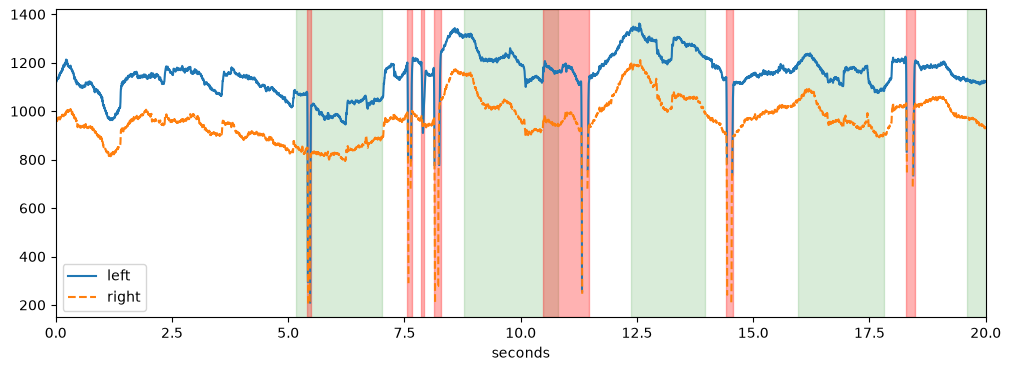

In [15]:
plt.figure(figsize=(12, 4))
d.plot.pupil_plot(plot_range=(0, 20) * u.sec, show_blinks=False,
                  show_events=False)
trials.to_units("sec").plot_highlight(color="green", alpha=0.15)
both_eyes.to_units("sec").plot_highlight(color="red", alpha=0.3)
plt.xlim(0, 20);

`d.plot.plot_intervals()` shows the data in each interval in a small
plot of its own, e.g., to check every blink (for blinks, `plot_blinks()`
does the same):

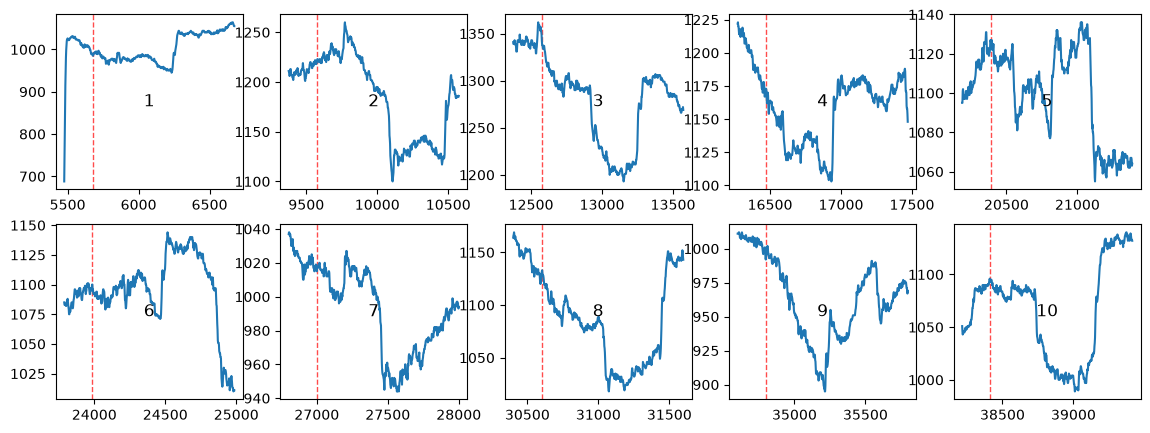

In [16]:
d.plot.plot_intervals(stim, eyes="left",
                      variables="pupil", nrow=2, ncol=5, figsize=(14, 5));

## Using intervals

Intervals are the input for many methods of the data objects.

**Masking and interpolating**: `mask_intervals()` marks the samples in
the intervals as invalid, `interpolate_intervals()` replaces them by
interpolated values. Here we mask the padded blinks in the pupil data:

In [17]:
d2 = d.mask_intervals(both_eyes.pad(50 * u.ms, 100 * u.ms),
                      variables="pupil", inplace=False)
d2.data.count_masked()

2791

**One value per interval**: `stat_per_event()` applies a function to the
data in each interval, e.g., the mean pupil size after each stimulus:

In [18]:
d2.stat_per_event(intervals=stim, variables="pupil")

{'left_pupil': array([1002.94259259, 1188.40377358, 1281.70833333, 1160.47666667,
        1100.505     , 1095.75166667,  993.23      , 1113.16718266,
         963.95833333, 1065.60833333]),
 'right_pupil': array([ 830.77222222,  977.68490566, 1095.90166667,  969.76      ,
         916.80833333,  920.42333333,  843.105     ,  932.6996904 ,
         808.225     ,  889.535     ])}

**Segments**: `get_segments()` cuts the data in each interval into a
`SegmentedEyeData` object, the basis for event-related pupil dilations
(see the [ERPD tutorial](erpds.ipynb)):

SegmentedEyeData(S_):
  variable      : left_pupil
  n_segments    : 10
  n_timepoints  : 600
  window        : (np.float64(-200.0), np.float64(1000.0))
  percent_masked: 6.78
  sampling_rate : 500.00
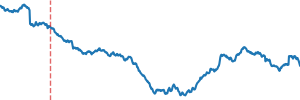

In [19]:
d2.get_segments(stim, "left_pupil")

## Masks and intervals

Intervals can be converted to a boolean mask with one entry per sample,
and back. Use `units=None` (sample indices) for this:

In [20]:
mask = both_eyes.to_units(None).to_mask(len(d))
print(mask.shape, mask.sum(), "samples in blinks")

pp.Intervals.from_mask(mask, units="ms", sampling_rate=d.fs)

(20465,) 1740 samples in blinks


Intervals | 15 intervals (total duration: 3480.00 ms), 232.00 ms +/- 232.02 ms, [48.00 ms, 984.00 ms] | fs=500.0Hz